# 07 3D 鱼轨迹生成（跨帧 + 跨视频 3D 个体追踪）

从 **tracking 处理后的 2D 数据**（player1/2/3 processed CSV）到水槽内 **每帧 3 个个体、跨视频统一 ID** 的 3D 轨迹完整流程。

**若使用 V2 跟踪数据**（`processed_v2` 目录）：请使用 **`06_trajectory_3d_v2.ipynb`**，其从 V2 的 2D 结果做 3D 重建并含静态图与视频可视化。

## 前置条件

- 已完成 **02 相机校准**（有 `imCoords_to_XYZ.joblib` 模型）
- 已完成 **04 跟踪后处理**（2D 内跨帧 ID 稳定、异常值按帧间隔去除、插值补全，得到 `*_player1_processed.csv` 等）

## 流程概览（跨帧 + 跨视频 3D 个体追踪）

1. **Step 1 点の取得**：从各相机 processed CSV 提取每帧 2D 点
2. **Step 2 3次元候補の計算**：用 2D→3D 模型对点组合计算 3D 候选及配准误差
3. **Step 3 最適な対応の選択**：基于配准误差选择最优 a/b/c 对应
4. **Step 4 跨帧个体追踪**：匈牙利 + 运动方向 flow，保证同一片段内同一物理个体时间上标签一致（a/b/c）
5. **导出 a/b/c 3D CSV**：每片段得到 `{set_key}_a_3d.csv` 等
6. **Step 5 跨视频/跨片段 ID 统一**：多片段时，为 a/b/c 赋予全局 **ID_1, ID_2, ID_3**（按片段顺序、边界 3D 位置 Hungarian 匹配）
7. **Step 6 3D 二次清理**：3D 轨迹按帧间隔缩放（一帧 10mm、两帧 20mm…）循环检测异常 → 剔除 → 插值，直到无异常，保证每帧都有 3 个个体

若只有单片段，可只跑 Step 1–4 + 导出；多片段时建议依次跑 Step 5、Step 6。

**若你重新跑过 04 的 2D 处理**：必须**重新运行本 notebook 的「四步骤算法」cell（Step 1→4 + 导出）**，否则 3D 仍会使用旧的 points.json / best.json / 3D CSV，可视化不会变。

**3D 身份与 ID 交换**：默认 Step 1 **不按** 2D 的 fish_0/1/2 取点，而按几何（score 或 x）排序；3D 身份由 **Step 3 几何最优对应** + **Step 4 跨帧 3D 追踪** 决定，从而避免 2D ID 交换传播到 3D，得到无 ID 交换的 3D 轨迹。若需 3D 与 2D 个体严格一致，可在 Step 1 中设 `use_fish_id=True`。


## 路径配置

In [1]:
from pathlib import Path
import sys

# 保证从 notebooks/ 或项目根运行都能 import scripts
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
else:
    for p in [ROOT] + list(ROOT.parents):
        if (p / "pyproject.toml").exists():
            ROOT = p
            break
sys.path.insert(0, str(ROOT))

# 校准模型目录：必须为 02 相机校准 notebook 保存 joblib 的文件夹（内含 imCoords_to_XYZ.joblib 等）
# 若报错 FileNotFoundError: imCoords_to_XYZ.joblib，请先运行 02_calibration 并把下面路径改为实际保存目录
MODEL_FOLDER = Path(r"D:\calibration_model\cali_251217_way1")  # 示例：02 里「模型将保存到」的路径
PROCESSED_DIR = Path(r"D:\sleap_output\processed")
OUTPUT_DIR = Path(r"D:\3d_trajectories")
SET_KEY = ""  # 可留空，自动从 processed 目录检测
SKIP_IF_EXISTS = True  # 已有 3D CSV 时跳过主流程，只跑可视化时设为 True

## 自动检测 set_key（若未指定）

In [2]:
if not SET_KEY and PROCESSED_DIR.exists():
    f = next(PROCESSED_DIR.glob("*_player1_processed.csv"), None)
    SET_KEY = f.stem.replace("_player1_processed", "") if f else ""
print("SET_KEY:", SET_KEY or "(未设置)")

SET_KEY: 20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331


## 四步骤算法（Step 1–4）

**重新算过 2D（04）后务必运行本 cell**，否则 3D 和可视化仍是旧结果。

- **Step 1**：从 processed CSV 提取每帧 2D 点 → `points.json`（默认不按 fish_0/1/2 排序，按几何 score/x；3D 身份由 Step 3+4 决定，可选 `use_fish_id=True` 与 2D 一致）
- **为何会出现 >200 的 3D 值？** 三视角点对应错误或校准模型外推时，会得到超出物理范围的坐标。设置 **`XYZ_BOUNDS = (0, 200)`**（或与校准范围一致）可把超出范围的候选视为无效，保证输出落在有效范围内。
- **Step 2**：用**校准模型**（`MODEL_FOLDER` 下的 `imCoords_to_XYZ.joblib` 等）把 2D 组合算成 3D 候选 → `candidates.json`  
  → 若报错 `FileNotFoundError: imCoords_to_XYZ.joblib`，请先运行 **02 相机校准**，并把上方 `MODEL_FOLDER` 改为 02 里保存 joblib 的目录。
- **Step 3**：按配准误差选最优 a/b/c 对应 → `best.json`
- **Step 4**：**跨帧个体追踪**（匈牙利 + 运动方向），保证同一物理个体在时间上保持同一标签 a/b/c

In [3]:
# 执行 Step 1→2→3→4：3D 身份由几何+跨帧追踪决定（use_fish_id=False），避免 2D ID 交换传到 3D
from scripts.reconstruction.step1_get_points import run as step1_run
from scripts.reconstruction.step2_compute_3d_candidates import run as step2_run
from scripts.reconstruction.step3_select_best_correspondence import run as step3_run
from scripts.reconstruction.step4_cross_frame_tracking import run as step4_run

POINTS_JSON = OUTPUT_DIR / "points.json"
CANDS_JSON = OUTPUT_DIR / "candidates.json"
BEST_JSON = OUTPUT_DIR / "best.json"

# 3D 有效范围（mm）：与校准/水槽一致，超出视为无效，避免出现 >200 等不合理值。不设则 XYZ_BOUNDS = None
XYZ_BOUNDS = (0, 200)  # 例如 (0, 200) 或 (0, 1200)，按实际校准范围修改

# Step 1: 点の取得（use_fish_id=False：不按 2D 身份排序，3D 身份由 Step3 几何+Step4 跨帧追踪决定）
_ = step1_run(str(PROCESSED_DIR), SET_KEY, str(POINTS_JSON), use_fish_id=False)

# Step 2: 3次元候補の計算（超出 XYZ_BOUNDS 的候选无效）
_ = step2_run(str(MODEL_FOLDER), str(POINTS_JSON), str(CANDS_JSON), xyz_bounds=XYZ_BOUNDS)

# Step 3: 最適な対応の選択（超出 XYZ_BOUNDS 不参与选择）
_ = step3_run(str(CANDS_JSON), str(BEST_JSON), xyz_bounds=XYZ_BOUNDS)

# Step 4: 跨帧个体追踪（匈牙利算法 + 运动方向 flow，保证同一物理个体时间上标签一致）
best = step4_run(str(BEST_JSON), str(BEST_JSON))

# 从 best.json 导出 a/b/c 三条 3D 轨迹为 CSV
from scripts.reconstruction.export_3d_groups import export_groups_to_csv

GROUP_CSVS = export_groups_to_csv(
    best_json_path=str(BEST_JSON),
    set_key=SET_KEY,
    output_dir=str(OUTPUT_DIR),
)


已保存: D:\3d_trajectories\points.json
共 929 帧待处理


Step2 3D候选: 100%|██████████| 929/929 [00:25<00:00, 36.61frame/s]


已保存: D:\3d_trajectories\candidates.json
已保存: D:\3d_trajectories\best.json
已保存: D:\3d_trajectories\best.json
已保存: D:\3d_trajectories\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_a_3d.csv
已保存: D:\3d_trajectories\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_b_3d.csv
已保存: D:\3d_trajectories\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_c_3d.csv


## Step 5 跨视频/跨片段 ID 统一（多片段时）

当 OUTPUT_DIR 下有**多个片段**的 `{set_key}_a_3d.csv` 时，运行 Step 5 可为 a/b/c 赋予全局 **ID_1, ID_2, ID_3**，使同一物理个体在不同片段中保持同一 ID。匹配方式：按 set_key 顺序，用上一片段最后一帧与当前片段第一帧的 3D 位置做 Hungarian 匹配。

In [4]:
# 多片段时运行：生成 {set_key}_ID_1_3d.csv, _ID_2_3d.csv, _ID_3_3d.csv
from scripts.reconstruction.step5_cross_video_id import run as step5_run

# set_keys 留空则自动扫描 OUTPUT_DIR 下所有 *_a_3d.csv 并按 key 排序
SET_KEYS_ORDERED = None  # 例如 ["clip1_key", "clip2_key"] 按时间顺序
step5_run(str(OUTPUT_DIR), set_keys=SET_KEYS_ORDERED)

  已写 20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331 -> ['ID_1', 'ID_2', 'ID_3']
  已写 20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277 -> ['ID_1', 'ID_2', 'ID_3']


['D:\\3d_trajectories\\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_ID_1_3d.csv',
 'D:\\3d_trajectories\\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_ID_2_3d.csv',
 'D:\\3d_trajectories\\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_ID_3_3d.csv',
 'D:\\3d_trajectories\\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277_ID_1_3d.csv',
 'D:\\3d_trajectories\\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277_ID_2_3d.csv',
 'D:\\3d_trajectories\\20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277_ID_3_3d.csv']

## Step 6 3D 异常值去除与插值补全（循环至无异常）

3D 坐标单位已为 **mm**。按帧间隔缩放阈值（一帧 > 10mm、两帧 > 20mm…）**循环**：检测异常 → 剔除 → 插值 → 再检测，直到无异常或达到最大迭代次数，保证每帧都有 3 个个体。与 2D 的迭代逻辑一致。若有 Step 5 生成的 ID_1/2/3 则优先处理，否则处理 a/b/c。

**下一步：** 运行下方「3D 轨迹可视化」→「生成 3D 轨迹视频 MP4」生成视频。

In [5]:
# 3D 二次清理：循环检测异常 → 剔除 → 插值，直到无异常（一帧 10mm，两帧 20mm…）
from scripts.reconstruction.step6_3d_outlier_interp import run as step6_run

MAX_MM_PER_FRAME = 5.0   # 每帧允许最大位移 (mm)，k 帧间隔阈值 = 10*k
MAX_ITERATIONS = 100      # 最大迭代次数
step6_run(
    str(OUTPUT_DIR),
    set_keys=None,
    max_mm_per_frame=MAX_MM_PER_FRAME,
    use_id_labels=True,
    in_place=True,
    max_iterations=MAX_ITERATIONS,
)

  已处理 20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331
  已处理 20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277


[WindowsPath('D:/3d_trajectories/20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_ID_1_3d.csv'),
 WindowsPath('D:/3d_trajectories/20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_ID_2_3d.csv'),
 WindowsPath('D:/3d_trajectories/20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Courtship_290.729-296.331_ID_3_3d.csv'),
 WindowsPath('D:/3d_trajectories/20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277_ID_1_3d.csv'),
 WindowsPath('D:/3d_trajectories/20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277_ID_2_3d.csv'),
 WindowsPath('D:/3d_trajectories/20251225_K_1_2_clips_20251225_K_1_2_FCMC_m1tf_Wrap_387.663-395.277_ID_3_3d.csv')]

## 3D 轨迹可视化

### 静态图预览（可选）

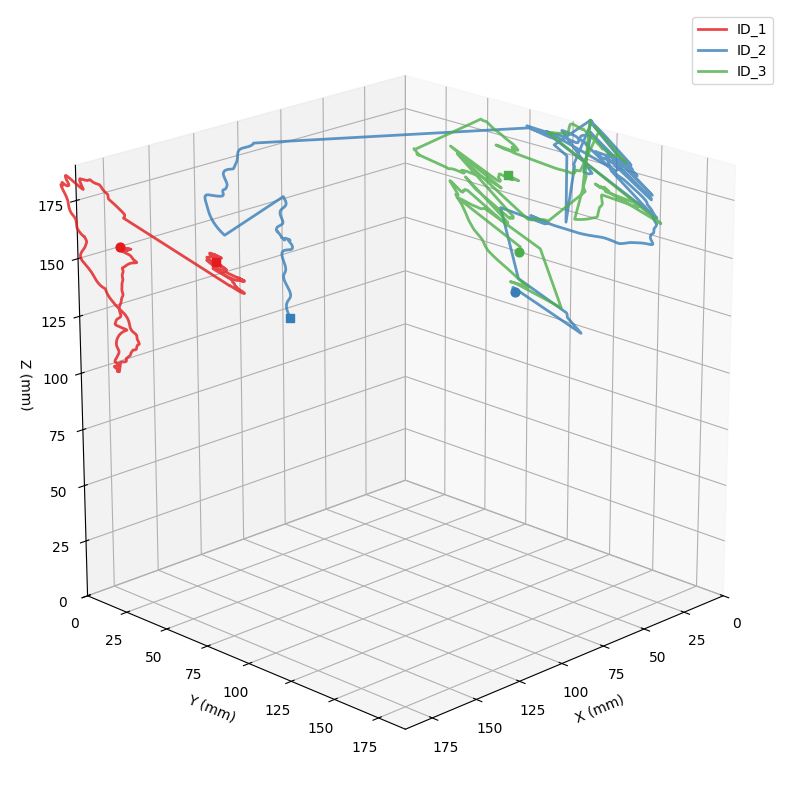

In [6]:
# 查看三条鱼的 3D 轨迹静态图（优先用 ID_1/2/3，否则 a/b/c）
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

labels = ["ID_1", "ID_2", "ID_3"] if (OUTPUT_DIR / f"{SET_KEY}_ID_1_3d.csv").exists() else ["a", "b", "c"]
colors = {"a": "#e41a1c", "b": "#377eb8", "c": "#4daf4a", "ID_1": "#e41a1c", "ID_2": "#377eb8", "ID_3": "#4daf4a"}
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

for label in labels:
    path = OUTPUT_DIR / f"{SET_KEY}_{label}_3d.csv"
    if not path.exists():
        continue
    df = pd.read_csv(path)
    x, y, z = df["X"].values, 190.0 - df["Y"].values, df["Z"].values
    ax.plot(x, y, z, "-", color=colors.get(label, "#333"), linewidth=2, alpha=0.8, label=label)
    if len(x) > 0:
        ax.scatter([x[0]], [y[0]], [z[0]], c=colors.get(label, "#333"), s=40, marker="o")
        ax.scatter([x[-1]], [y[-1]], [z[-1]], c=colors.get(label, "#333"), s=40, marker="s")

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_xlim(0, 190)
ax.set_ylim(0, 190)
ax.set_zlim(0, 190)
ax.view_init(elev=20, azim=45)
try:
    ax.set_box_aspect([1, 1, 1])
except Exception:
    pass
ax.legend()
plt.tight_layout()
plt.show()

### 生成 3D 轨迹视频 MP4，叠加原始视频（从已有 CSV）

需安装ffmpeg（或  imageio-ffmpeg）。输出：`{SET_KEY}_3d_trajectories.mp4`

In [8]:
from scripts.reconstruction.visualize_3d import run_video

# 输出视频 fps 控制播放速度：fps=30 为慢速便于观看（原视频 166 则约 5.5 倍慢放）；subsample 为帧间隔
out_mp4 = run_video(str(OUTPUT_DIR), SET_KEY, fps=30, subsample=10)
print("视频已保存:", out_mp4)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (926, 946) to (928, 960) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


ValueError: All images in a movie should have same size

---